<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/Experiment%2023%3A%20Bayesian%20Network%20Construction%20and%20Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Model Valid: True


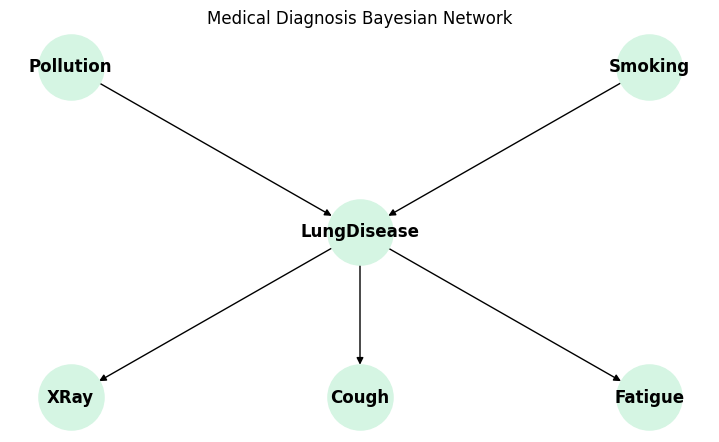

Independencies:
 (Fatigue ⟂ Smoking | LungDisease)
(Cough ⟂ XRay | LungDisease)
(Pollution ⟂ XRay | LungDisease)
(Fatigue ⟂ Pollution | LungDisease)
(Cough ⟂ Fatigue | LungDisease)
(Fatigue ⟂ XRay | LungDisease)
(Smoking ⟂ XRay | LungDisease)
(Cough ⟂ Smoking | LungDisease)
(Pollution ⟂ Smoking)
(Cough ⟂ Pollution | LungDisease)
Active Trails from Smoking given LungDisease: {'Smoking': {'Smoking', 'Pollution'}}


In [2]:
import subprocess, sys
try:
    import pgmpy
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pgmpy"])

import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

bn = DiscreteBayesianNetwork([('Pollution', 'LungDisease'), ('Smoking', 'LungDisease'),
                              ('LungDisease', 'XRay'), ('LungDisease', 'Cough'), ('LungDisease', 'Fatigue')])

bn.add_cpds(
    TabularCPD('Pollution', 2, [[0.9], [0.1]], state_names={'Pollution': ['Low', 'High']}),
    TabularCPD('Smoking', 2, [[0.7], [0.3]], state_names={'Smoking': ['No', 'Yes']}),
    TabularCPD('LungDisease', 2, [[0.99, 0.90, 0.95, 0.70], [0.01, 0.10, 0.05, 0.30]],
               evidence=['Pollution', 'Smoking'], evidence_card=[2, 2],
               state_names={'LungDisease': ['No', 'Yes'], 'Pollution': ['Low', 'High'], 'Smoking': ['No', 'Yes']}),
    TabularCPD('XRay', 2, [[0.95, 0.20], [0.05, 0.80]], evidence=['LungDisease'], evidence_card=[2],
               state_names={'XRay': ['Neg', 'Pos'], 'LungDisease': ['No', 'Yes']}),
    TabularCPD('Cough', 2, [[0.85, 0.25], [0.15, 0.75]], evidence=['LungDisease'], evidence_card=[2],
               state_names={'Cough': ['No', 'Yes'], 'LungDisease': ['No', 'Yes']}),
    TabularCPD('Fatigue', 2, [[0.80, 0.30], [0.20, 0.70]], evidence=['LungDisease'], evidence_card=[2],
               state_names={'Fatigue': ['No', 'Yes'], 'LungDisease': ['No', 'Yes']})
)

print("Model Valid:", bn.check_model())

plt.figure(figsize=(7, 4))
pos = {'Pollution': (0, 2), 'Smoking': (2, 2), 'LungDisease': (1, 1), 'XRay': (0, 0), 'Cough': (1, 0), 'Fatigue': (2, 0)}
nx.draw(bn, pos, with_labels=True, node_size=2200, node_color='#D5F5E3', font_weight='bold')
plt.title("Medical Diagnosis Bayesian Network")
plt.show()

print("Independencies:\n", bn.get_independencies())
print("Active Trails from Smoking given LungDisease:", bn.active_trail_nodes('Smoking', observed=['LungDisease']))